In [26]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
import math
from dask.distributed import Client
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib import cm
import warnings
warnings.filterwarnings('ignore')
from collections import defaultdict
from pathlib import Path
sys.path.append('/home/563/sc1326/repos/cdrmip_extremes')
from cdrmip_extremes.configs import data_dir, proc_dir
from cdrmip_extremes.sat import find_crossing_years, find_matching_gwls
from cdrmip_extremes import processing, utils, ext_freq, load_processed
from cdrmip_extremes.CMIP6_file_search import find_CMIP_files, search_and_load, search_and_load_parent, concatenate_branches

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [5]:
gsat_dt = load_processed.load_processed(proc_dir, 'ScenarioMIP', 'anomalies', 'gsat', chunks=None,average_members=False)

Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies/ACCESS-CM2/ACCESS-CM2_ssp126_r1i1p1f1_gsat_anomalies.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp126_r10i1p1f1_gsat_anomalies.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp126_r11i1p1f1_gsat_anomalies.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp126_r12i1p1f1_gsat_anomalies.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp126_r13i1p1f1_gsat_anomalies.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp126_r14i1p1f1_gsat_anomalies.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies

In [6]:
anomaly_dt = load_processed.load_processed(proc_dir, 'ScenarioMIP', 'anomalies', 'tas', chunks=None)

Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-CM2/ACCESS-CM2_ssp126_r1i1p1f1_tas_anomalies.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp126_r10i1p1f1_tas_anomalies.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp126_r11i1p1f1_tas_anomalies.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp126_r12i1p1f1_tas_anomalies.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp126_r13i1p1f1_tas_anomalies.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp126_r14i1p1f1_tas_anomalies.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-ESM1-

### Calculate rolling gsat average

In [7]:
window=21
gsat_rolling_dt = gsat_dt.map_over_datasets(
    lambda ds: utils.rolling(ds, window=window) if 'year' in ds.dims or 'time' in ds.dims else ds
)

## Find Equivalent GWL years

### Start with end of 22nd century GSAT

In [55]:
TARGET_EXPTS = {'ssp126', 'ssp534-over'}
POST_SLICE = slice(2170, 2201)
ssp_equiv_gwl_years, ssp_gwl_differences = {}, {}
for model, expt_dt in gsat_rolling_dt.items():
    for expt, member_dt in expt_dt.items():
        if expt not in TARGET_EXPTS:
            continue
        for member, dt in member_dt.items():
            ds = dt.ds.gsat
            post_gwl = np.round(float(ds.sel(year=POST_SLICE).mean('year')), 2)
            pre_gwl_year = ds.where(ds > post_gwl).dropna('year').year[0]
            print(f"{model} {expt} {member} {post_gwl} {pre_gwl_year.values}")

            anom_ds = anomaly_dt[model][expt][member].ds.tas
            ssp_equiv_gwl_years.setdefault(model, {}).setdefault(expt, {})[member] = {'gwl': post_gwl, 'pre_gwl_year': pre_gwl_year}
            ssp_gwl_differences.setdefault(model, {}).setdefault(expt, {})[member] = (
                anom_ds.sel(year=POST_SLICE).mean('year')
                - anom_ds.sel(year=slice(pre_gwl_year - 15, pre_gwl_year + 16)).mean('year')
            )

ACCESS-CM2 ssp126 r1i1p1f1 2.4 2067
ACCESS-ESM1-5 ssp126 r10i1p1f1 1.87 2050
ACCESS-ESM1-5 ssp126 r11i1p1f1 1.83 2047
ACCESS-ESM1-5 ssp126 r12i1p1f1 1.85 2047
ACCESS-ESM1-5 ssp126 r13i1p1f1 1.86 2046
ACCESS-ESM1-5 ssp126 r14i1p1f1 1.79 2052
ACCESS-ESM1-5 ssp126 r15i1p1f1 1.96 2054
ACCESS-ESM1-5 ssp126 r16i1p1f1 1.92 2055
ACCESS-ESM1-5 ssp126 r17i1p1f1 1.88 2051
ACCESS-ESM1-5 ssp126 r18i1p1f1 1.81 2045
ACCESS-ESM1-5 ssp126 r19i1p1f1 1.81 2044
ACCESS-ESM1-5 ssp126 r1i1p1f1 1.83 2058
ACCESS-ESM1-5 ssp126 r20i1p1f1 1.86 2055
ACCESS-ESM1-5 ssp126 r21i1p1f1 1.87 2042
ACCESS-ESM1-5 ssp126 r22i1p1f1 1.93 2047
ACCESS-ESM1-5 ssp126 r23i1p1f1 1.82 2051
ACCESS-ESM1-5 ssp126 r24i1p1f1 1.89 2051
ACCESS-ESM1-5 ssp126 r25i1p1f1 1.93 2051
ACCESS-ESM1-5 ssp126 r26i1p1f1 1.99 2057
ACCESS-ESM1-5 ssp126 r27i1p1f1 1.71 2044
ACCESS-ESM1-5 ssp126 r28i1p1f1 1.67 2041
ACCESS-ESM1-5 ssp126 r29i1p1f1 1.79 2042
ACCESS-ESM1-5 ssp126 r2i1p1f1 1.89 2054
ACCESS-ESM1-5 ssp126 r30i1p1f1 1.94 2056
ACCESS-ESM1-5 ssp126 r3

## Plot

In [9]:
models = list(anomaly_dt.keys())
models

['ACCESS-CM2',
 'ACCESS-ESM1-5',
 'CAMS-CSM1-0',
 'CESM2-WACCM',
 'CNRM-ESM2-1',
 'CanESM5',
 'EC-Earth3',
 'EC-Earth3-Veg',
 'GFDL-ESM4',
 'GISS-E2-1-G',
 'GISS-E2-1-H',
 'GISS-E2-2-G',
 'IPSL-CM6A-LR',
 'MIROC-ES2L',
 'MIROC6',
 'MRI-ESM2-0',
 'UKESM1-0-LL']

In [10]:
cmap = plt.cm.get_cmap('tab10')
colour_dict = {model: cmap(i / len(models)) for i, model in enumerate(models)}

ssp_colour_dict = {
    'ssp126':'blue',
    'ssp534-over':'darkred',
    'ssp119':'lightgreen'
}

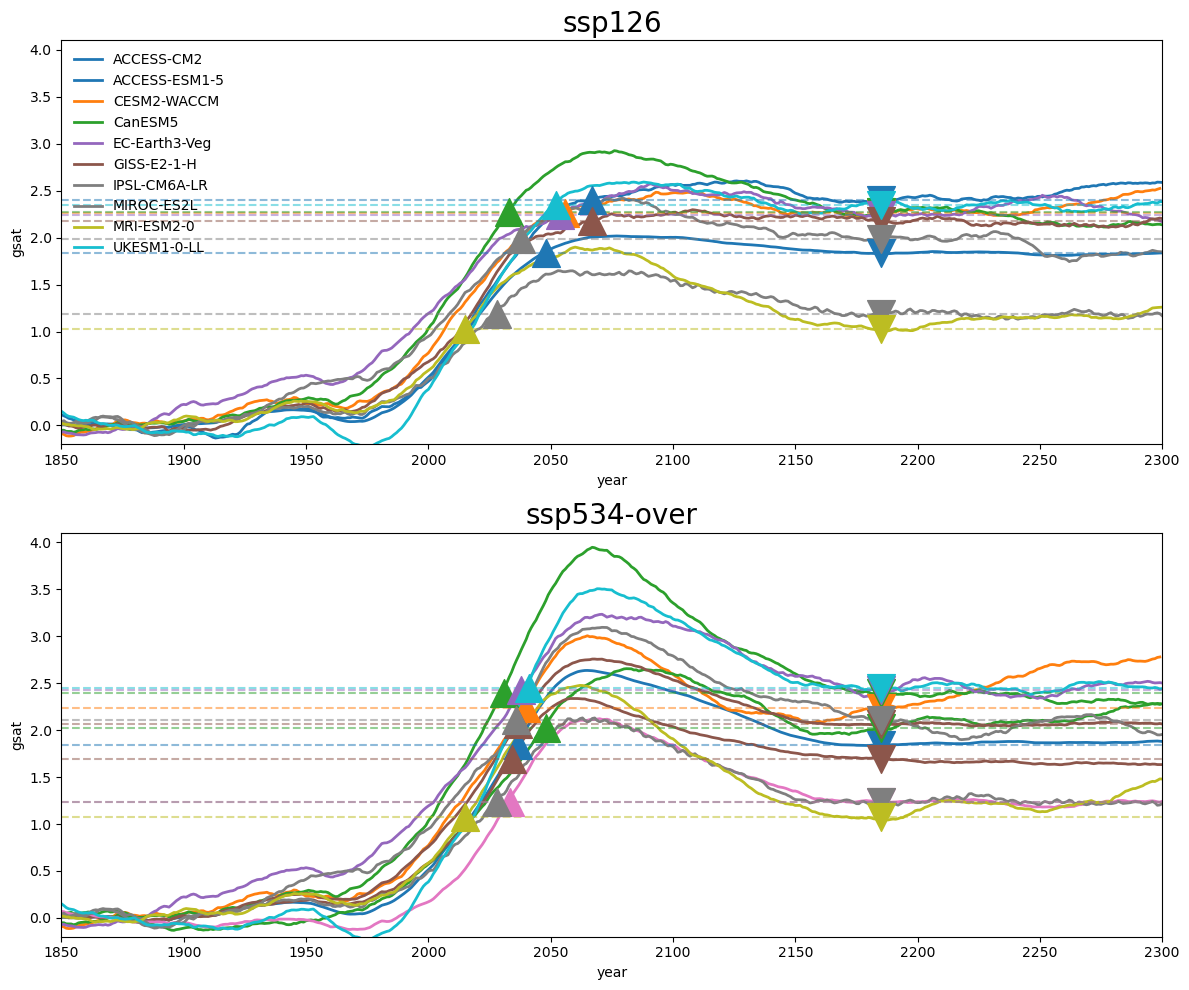

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

for model, expt_dt in gsat_rolling_dt.items():
    for expt, member_dt in expt_dt.items():
        if expt not in TARGET_EXPTS:
            continue
        ax = axes[0] if expt == 'ssp126' else axes[1]
        member_das = [dt.ds.gsat for dt in member_dt.values()]
        mean_da = xr.concat(member_das, dim='member').mean('member')
        mean_da.plot(ax=ax, label=model, linewidth=2, color=colour_dict[model])
        ax.set_ylim([-0.2,4.1])

for model, expt_dict in ssp_equiv_gwl_years.items():
    for expt, member_dict in expt_dict.items():
        ax = axes[0] if expt == 'ssp126' else axes[1]
        post_gwl = np.mean([d['gwl'] for d in member_dict.values()])
        pre_gwl_year = np.mean([d['pre_gwl_year'] for d in member_dict.values()])
        ax.axhline(y=post_gwl,color=colour_dict[model],linestyle='--',alpha=0.5)
        ax.scatter(2185, post_gwl, color=colour_dict[model], marker='v', s=400, zorder=5)
        ax.scatter(pre_gwl_year, post_gwl, color=colour_dict[model], marker='^', s=400, zorder=5)

handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
axes[0].legend(unique.values(), unique.keys(), frameon=False)
axes[0].set_title('ssp126', fontsize=20)
axes[1].set_title('ssp534-over', fontsize=20)

for ax in axes.flat:
    ax.set_xlim([1850, 2300])

fig.tight_layout()

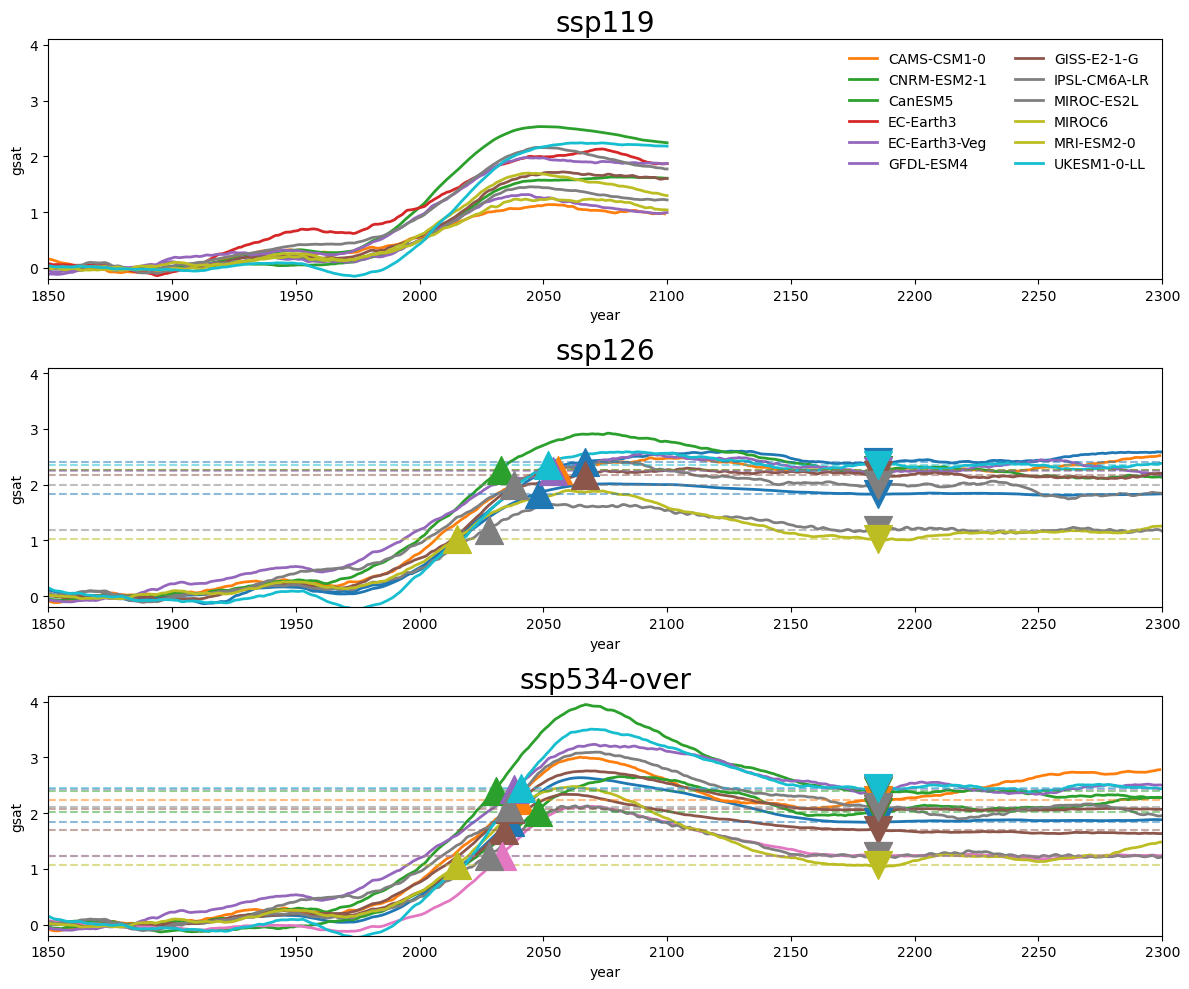

In [39]:

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

ax_dict = {
    'ssp119':axes[0],
    'ssp126':axes[1],
    'ssp534-over':axes[2]
}

for model, expt_dt in gsat_rolling_dt.items():
    for expt, member_dt in expt_dt.items():
        ax = ax_dict[expt]
        member_das = [dt.ds.gsat for dt in member_dt.values()]
        mean_da = xr.concat(member_das, dim='member').mean('member')
        mean_da.plot(ax=ax, label=model, linewidth=2, color=colour_dict[model])
        ax.set_ylim([-0.2,4.1])
        ax.set_title(expt,fontsize=20)

for model, expt_dict in ssp_equiv_gwl_years.items():
    for expt, member_dict in expt_dict.items():
        ax = ax_dict[expt]
        post_gwl = np.mean([d['gwl'] for d in member_dict.values()])
        pre_gwl_year = np.mean([d['pre_gwl_year'] for d in member_dict.values()])
        ax.axhline(y=post_gwl,color=colour_dict[model],linestyle='--',alpha=0.5)
        ax.scatter(2185, post_gwl, color=colour_dict[model], marker='v', s=400, zorder=5)
        ax.scatter(pre_gwl_year, post_gwl, color=colour_dict[model], marker='^', s=400, zorder=5)

handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
axes[0].legend(unique.values(), unique.keys(), frameon=False,ncol=2)


for ax in axes.flat:
    ax.set_xlim([1850, 2300])

fig.tight_layout()

## Plot ssp_gwl_differences

### first calculate ensemble means

In [36]:
gwl_diffs = defaultdict(dict)
for model, expt_dict in ssp_gwl_differences.items():
    for expt, member_dict in expt_dict.items():
        member_list = [ds.assign_coords(member=member) for ds in member_dict.values()]
        ens_mean = xr.concat(member_list,dim='member').mean(dim='member')
        gwl_diffs[model][expt] = ens_mean.load()
gwl_diffs = dict(gwl_diffs)

In [38]:
# want median across models for both expts

model_keys = [m for m in gwl_diffs.keys() if m != 'Multi-Model Median']

gwl_diffs['Multi-Model Median'] = {
    expt: xr.concat(
        [
            gwl_diffs[model][expt]
            for model in model_keys
            if expt in gwl_diffs[model]
        ],
        dim='model',
        coords='minimal',
        compat='override'
    ).median(dim='model')
    for expt in ['ssp534-over','ssp126']
}


In [27]:
def plot_gwl_diff(data_dict,expt):
    
    to_plot = {
        model : expt_dict[expt]  for model, expt_dict in data_dict.items() if expt in expt_dict.keys()
    }
    
    n_plots = len(to_plot)
    n_cols = 3
    n_rows = math.ceil(n_plots / n_cols)
    
    fig, axes = plt.subplots(
        n_rows, n_cols,
        subplot_kw={'projection': ccrs.Robinson()},
        figsize=(16, n_rows * 10/3),
        sharey=True,
    )
    
    levels = np.linspace(-1, 1, 21)
    cmap = cm.RdBu_r
    norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)
    
    for (model, ds), ax in zip(to_plot.items(), axes.flat):
        lat, lon = ds.lat, ds.lon
        mesh = ax.pcolormesh(
            lon, lat, ds,
            transform=ccrs.PlateCarree(),
            cmap=cmap,
            norm=norm,
        )
        ax.coastlines()
        ax.set_title(model, fontsize=16)
    
    # Hide unused axes
    for ax in axes.flat[n_plots:]:
        ax.set_visible(False)
    cbar_kwargs = {
            "fraction": 0.02, "aspect": 20,
            "label": "% Years", 'orientation': 'horizontal',
            'location': 'bottom', 'pad': 0.01,
            'anchor': (0.5, -4), 'extend': 'both'
        }
    cbar_ax = fig.add_axes([0.1, -0.05, 0.8, 0.04])
    cbar = fig.colorbar(mesh, cax=cbar_ax, **cbar_kwargs)
    cbar.ax.tick_params(labelsize=14)
    cbar.set_label("SAT Difference", fontsize=16)
    
    fig.suptitle(f'{expt} differences post vs pre-peak warming', fontsize=22)
    fig.tight_layout()

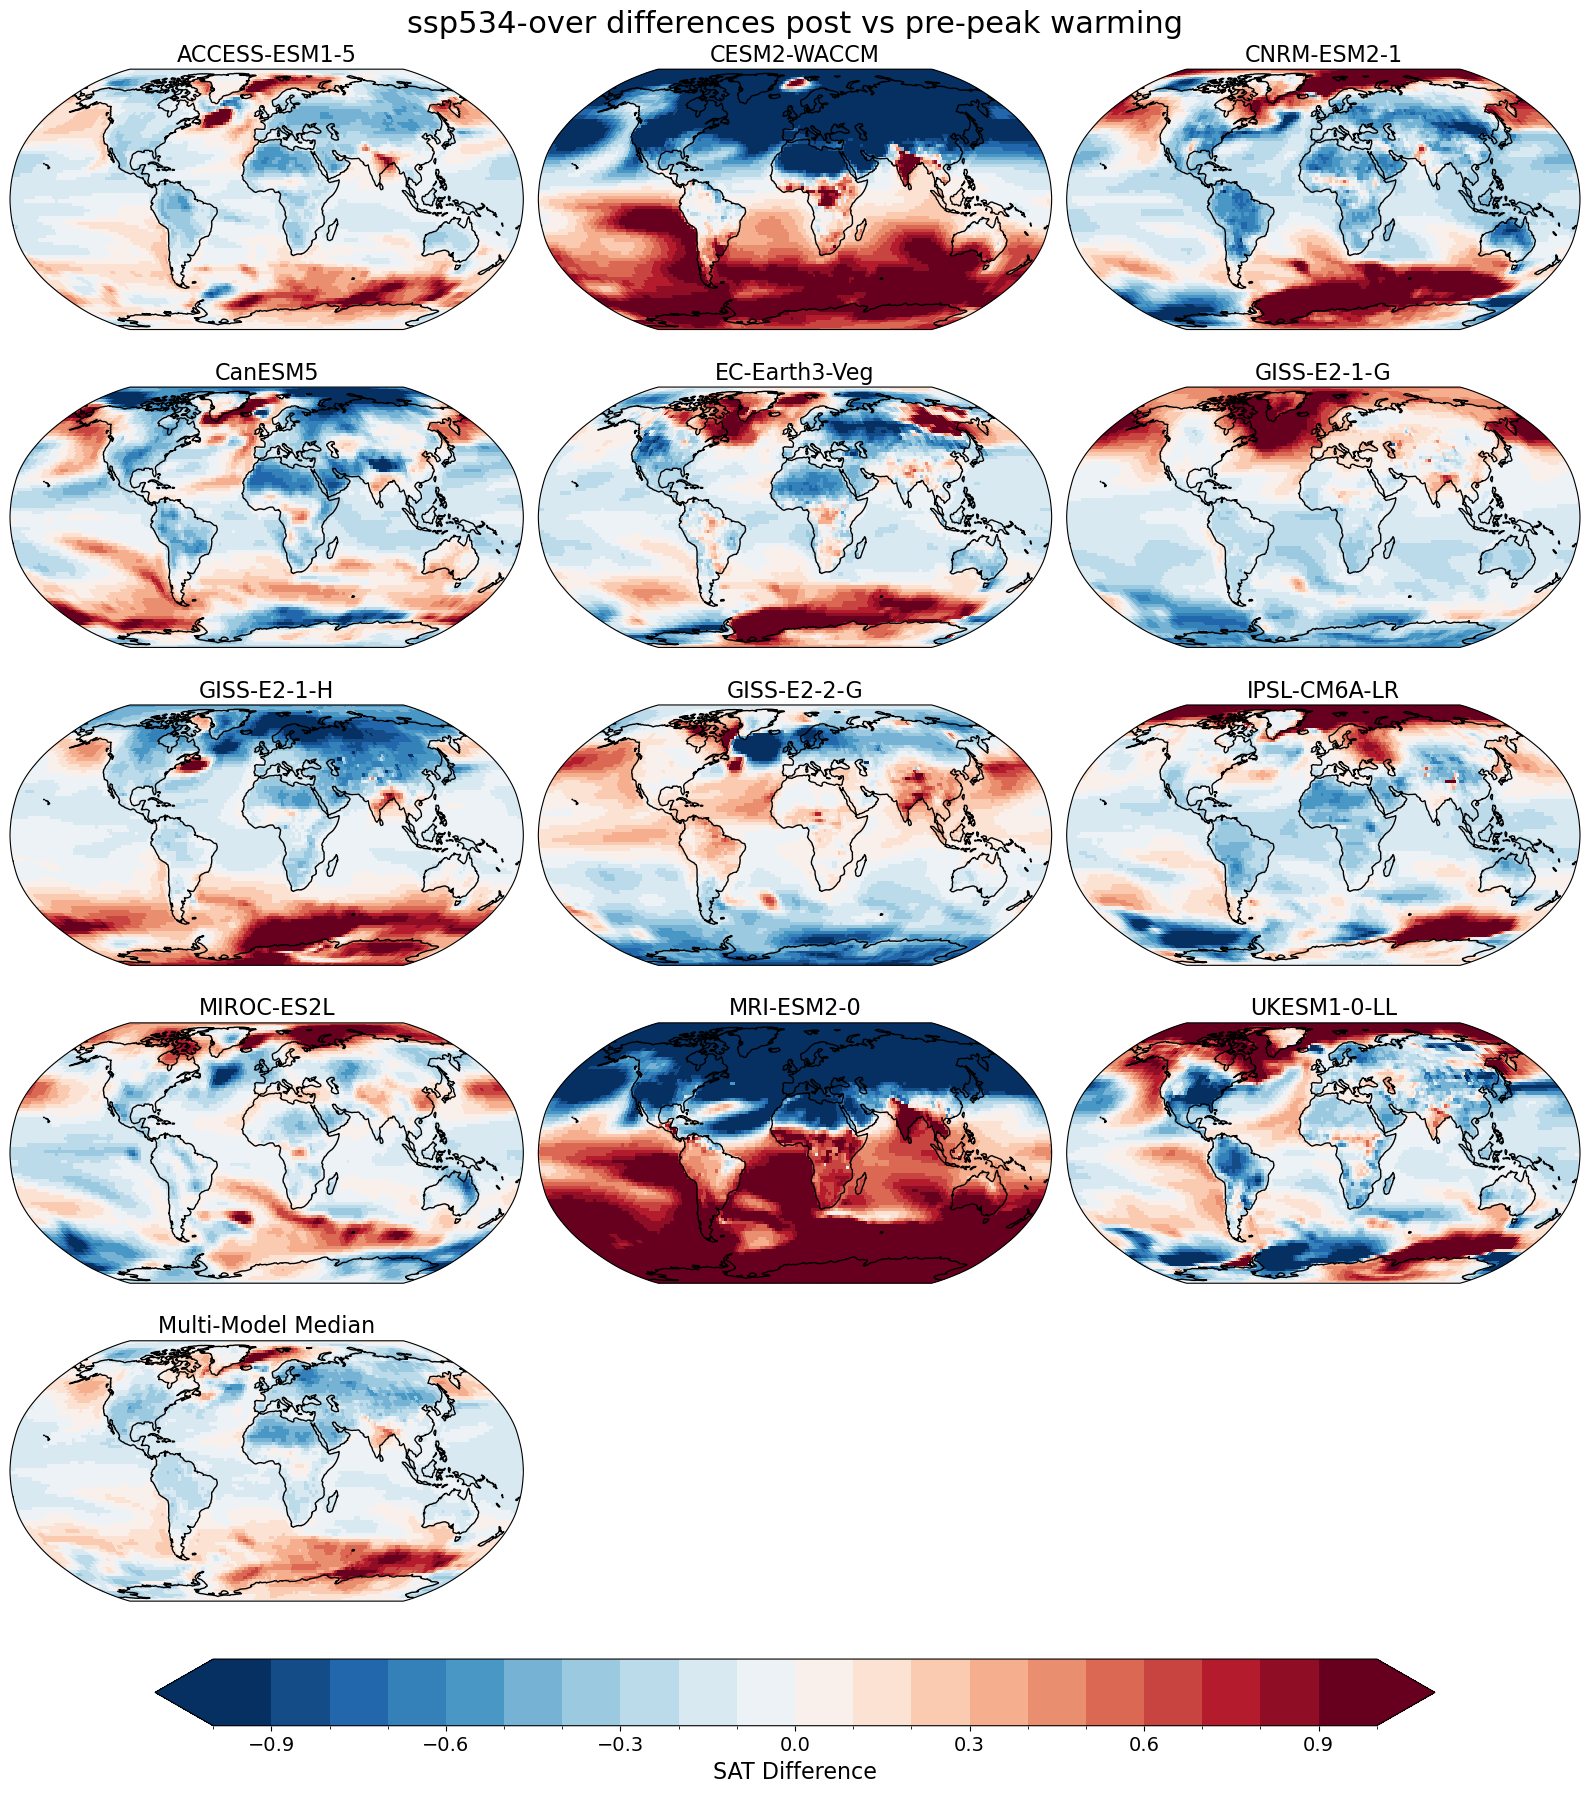

In [35]:
plot_gwl_diff(gwl_diffs,'ssp534-over')

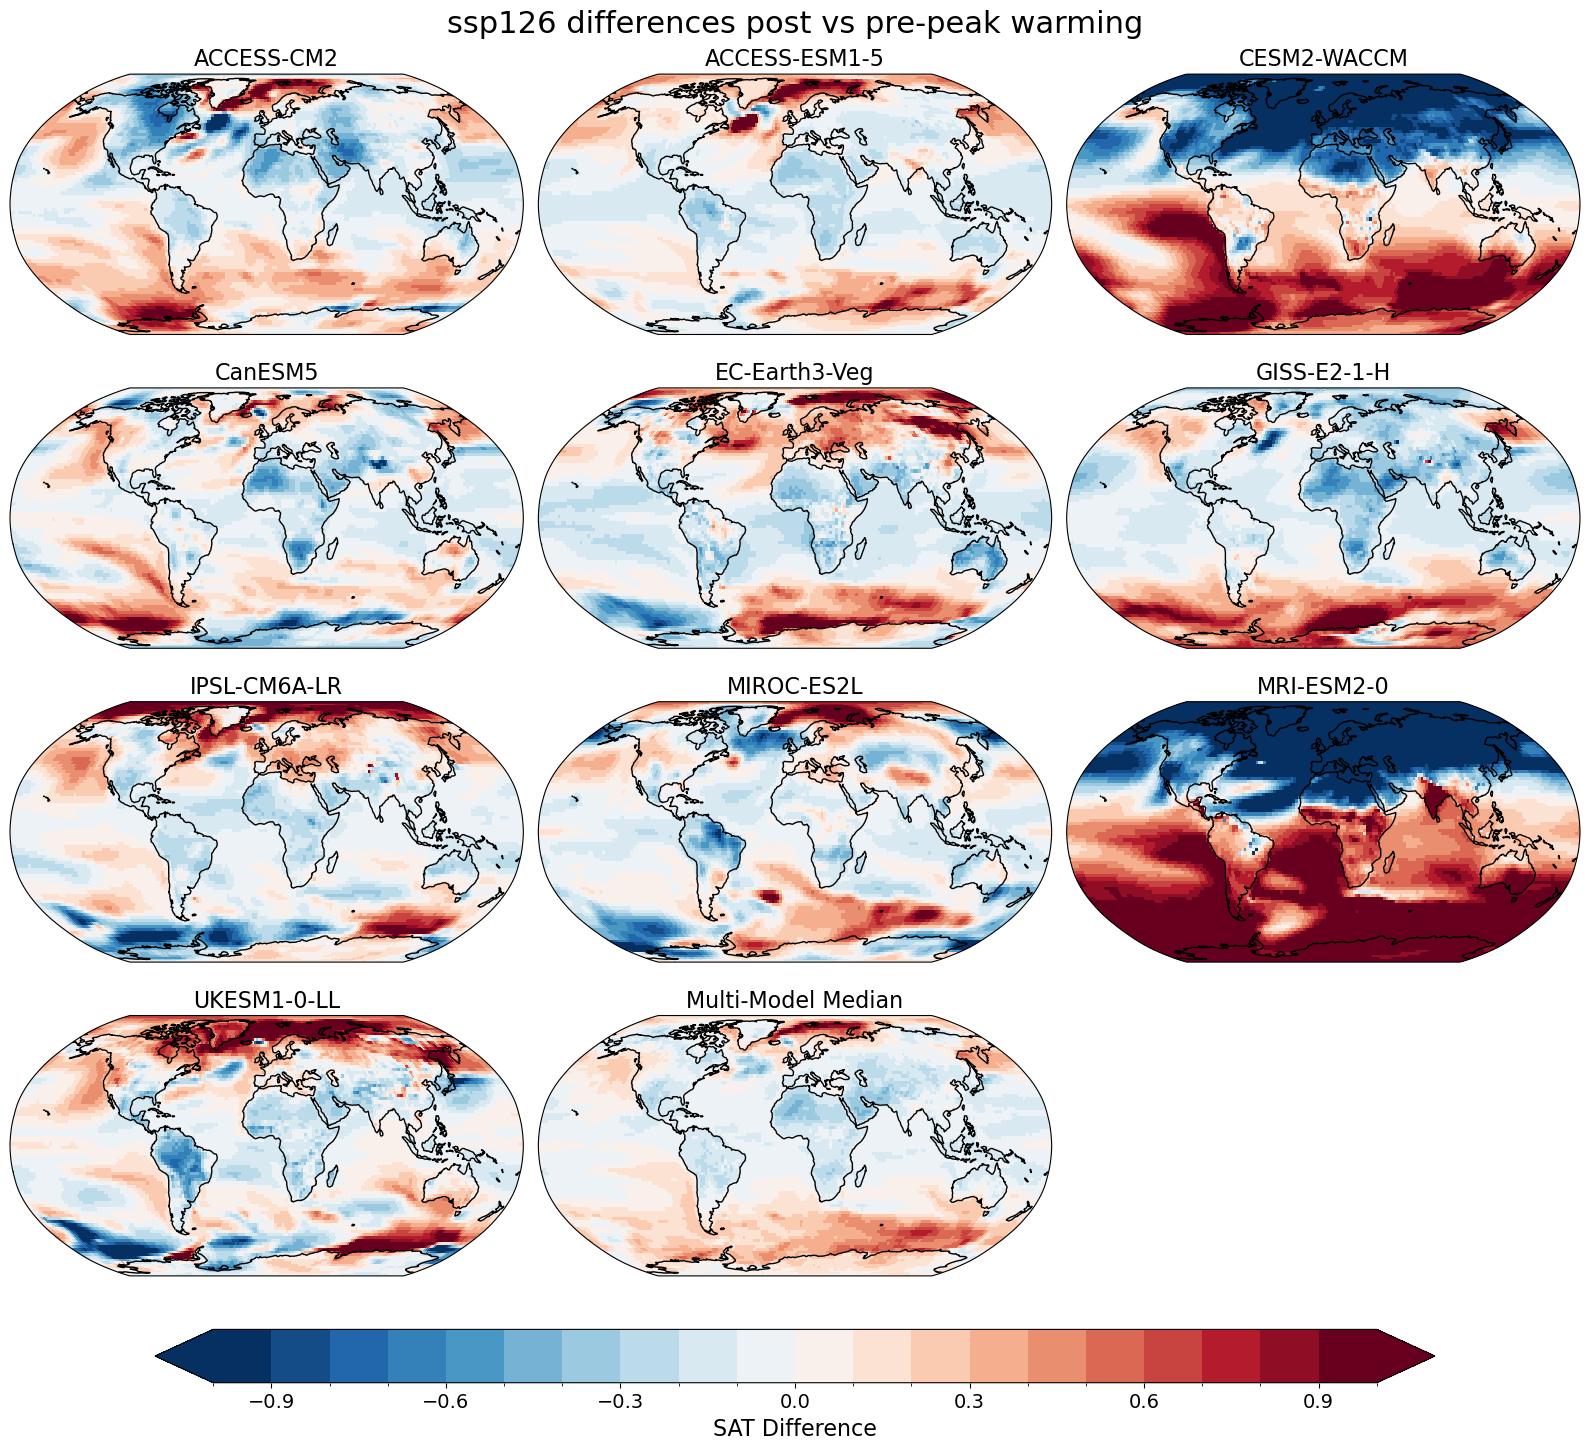

In [41]:
plot_gwl_diff(gwl_diffs,'ssp126')

## Save

In [56]:
# first convert ssp_equiv_gwl_years to dataset
records = []
for model, expt_dict in ssp_equiv_gwl_years.items():
    for expt, member_dict in expt_dict.items():
        for member, vals in member_dict.items():
            pre_gwl_year = vals['pre_gwl_year']
            # unwrap to plain python scalar if it's a DataArray
            if isinstance(pre_gwl_year, xr.DataArray):
                pre_gwl_year = int(pre_gwl_year.item())
            records.append({
                'model': model,
                'expt': expt,
                'member': member,
                'gwl': vals['gwl'],
                'pre_gwl_year': pre_gwl_year,
                'post_gwl_year':2185 # this is the same for every run by definition
            })

df = pd.DataFrame(records)

gwl_years = (
    df.set_index(['model', 'expt', 'member'])
      .to_xarray()
)

gwl_years

<xarray.Dataset> Size: 54kB
Dimensions:        (model: 13, expt: 2, member: 85)
Coordinates:
  * model          (model) object 104B 'ACCESS-CM2' ... 'UKESM1-0-LL'
  * expt           (expt) object 16B 'ssp126' 'ssp534-over'
  * member         (member) object 680B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p1f2'
Data variables:
    gwl            (model, expt, member) float64 18kB nan nan nan ... nan nan
    pre_gwl_year   (model, expt, member) float64 18kB nan nan nan ... nan nan
    post_gwl_year  (model, expt, member) float64 18kB nan nan nan ... nan nan

In [57]:
save_dir = proc_dir / "ScenarioMIP" / "gwl_years"
os.makedirs(save_dir,exist_ok=True)
path = save_dir / "gwl_years.nc"
gwl_years.to_netcdf(path)

# Save GWL differences

In [59]:
gwl_diffs

{'ACCESS-CM2': {'ssp126': <xarray.DataArray 'tas' (lat: 90, lon: 180)> Size: 65kB
  array([[ 0.18721223,  0.18906474,  0.1919496 , ...,  0.18262959,
           0.18413234,  0.1870935 ],
         [ 0.3076737 ,  0.30681443,  0.30713868, ...,  0.29538321,
           0.30239868,  0.30495763],
         [ 0.43218255,  0.43349934,  0.43126464, ...,  0.43379998,
           0.4362049 ,  0.43072462],
         ...,
         [ 0.09475088,  0.08001089,  0.06207371, ...,  0.1337676 ,
           0.11972904,  0.10210896],
         [-0.11554766, -0.12447119, -0.13321972, ..., -0.09397078,
          -0.09957075, -0.11102819],
         [-0.23694468, -0.23854399, -0.2397933 , ..., -0.2334814 ,
          -0.23357391, -0.23567343]], dtype=float32)
  Coordinates:
    * lat      (lat) float64 720B -89.5 -87.49 -85.48 -83.47 ... 85.48 87.49 89.5
    * lon      (lon) float64 1kB -179.5 -177.5 -175.5 -173.5 ... 175.5 177.5 179.5},
 'ACCESS-ESM1-5': {'ssp126': <xarray.DataArray 'tas' (lat: 90, lon: 180)> Size: 65

In [61]:
save_dir = proc_dir / "ScenarioMIP" / "tas_differences"
for model, expt_dict in gwl_diffs.items():
    for expt, ds in expt_dict.items():
        # save
        expt_dir = save_dir / model / expt
        os.makedirs(expt_dir,exist_ok=True)
        path = expt_dir / f"{model}_{expt}_tas_gwl_difference.nc"
        if path.exists():
            print(f"Skipping (already exists): {path}")
            continue
        print(f"Saving to {path}")
        ds.to_netcdf(path)

Saving to /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas_differences/ACCESS-CM2/ssp126/ACCESS-CM2_ssp126_tas_gwl_difference.nc
Saving to /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas_differences/ACCESS-ESM1-5/ssp126/ACCESS-ESM1-5_ssp126_tas_gwl_difference.nc
Saving to /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas_differences/ACCESS-ESM1-5/ssp534-over/ACCESS-ESM1-5_ssp534-over_tas_gwl_difference.nc
Saving to /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas_differences/CESM2-WACCM/ssp126/CESM2-WACCM_ssp126_tas_gwl_difference.nc
Saving to /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas_differences/CESM2-WACCM/ssp534-over/CESM2-WACCM_ssp534-over_tas_gwl_difference.nc
Saving to /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas_differences/CNRM-ESM2-1/ssp534-over/CNRM-ESM2-1_ssp534-over_tas_gwl_difference.nc
Saving to /home/563/sc1326/repos/cdrmip_extremes/dat